# ChronoClone × Weinreb 2020 — Comprehensive Analysis Pipeline
**Dataset:** Weinreb et al. Science 367, eaaw3381 (2020)
**GEO Accession:** GSE140802

This notebook executes the ChronoClone analysis on the Weinreb 2020 LARRY dataset to identify metaclonal structure during multilineage differentiation.

In [ ]:
import sys
import os
import urllib.request
# Add local chronoclone source to path to prioritize it over site-packages (resolves quota/ImportError issues)
local_cc_path = os.path.abspath('ChronoClone')
if local_cc_path not in sys.path:
    sys.path.insert(0, local_cc_path)

import chronoclone as cc
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.io
import scipy.sparse
import gzip

# Setting matplotlib parameters for paper-quality figures
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']

## 0. Data Acquisition and Preprocessing
Load all published in vitro data files from Weinreb et al. 2020 and construct the AnnData object.

**Published data files (Experiment 1: In vitro differentiation, days 2, 4, 6):**
1. `stateFate_inVitro_normed_counts.mtx.gz` — L1-normalized UMI counts (cells × genes)
2. `stateFate_inVitro_gene_names.txt.gz` — Gene symbols
3. `stateFate_inVitro_clone_matrix.mtx.gz` — Binary clone membership matrix
4. `stateFate_inVitro_metadata.txt.gz` — Cell metadata (Library, Cell barcode, Time point, Starting population, Cell type annotation, Well, SPRING-x/y)
5. `stateFate_inVitro_neutrophil_pseudotime.txt.gz` — Pseudotime for neutrophil trajectory cells
6. `stateFate_inVitro_neutrophil_monocyte_trajectory.txt.gz` — Cells in neutrophil/monocyte trajectory

**Source:** [AllonKleinLab/paper-data](https://github.com/AllonKleinLab/paper-data/tree/master/Lineage_tracing_on_transcriptional_landscapes_links_state_to_fate_during_differentiation)

In [ ]:
# === 0a. Ensure all published data files are present ===
data_dir = '../raw_data'
base_url = 'https://kleintools.hms.harvard.edu/paper_websites/state_fate2020/'

# Bypass SSL certificate verification for downloads
import ssl
ssl._create_default_https_context = ssl._create_unverified_context

# All 6 published in vitro data files
required_files = [
    'stateFate_inVitro_normed_counts.mtx.gz',
    'stateFate_inVitro_gene_names.txt.gz',
    'stateFate_inVitro_metadata.txt.gz',
    'stateFate_inVitro_clone_matrix.mtx.gz',
    'stateFate_inVitro_neutrophil_pseudotime.txt.gz',
    'stateFate_inVitro_neutrophil_monocyte_trajectory.txt.gz',
]

for fname in required_files:
    fpath = os.path.join(data_dir, fname)
    if not os.path.exists(fpath):
        url = base_url + fname
        print(f"Downloading {fname}...")
        urllib.request.urlretrieve(url, fpath)
        print(f"  Saved ({os.path.getsize(fpath):,} bytes)")
    else:
        print(f"  {fname} already present ({os.path.getsize(fpath):,} bytes)")

print("\nAll 6 published in vitro data files are available.")

  stateFate_inVitro_normed_counts.mtx.gz already present (2,065,554,808 bytes)
  stateFate_inVitro_gene_names.txt.gz already present (65,687 bytes)
  stateFate_inVitro_metadata.txt.gz already present (2,214,511 bytes)
  stateFate_inVitro_clone_matrix.mtx.gz already present (197,714 bytes)
  stateFate_inVitro_neutrophil_pseudotime.txt.gz already present (312,014 bytes)
  stateFate_inVitro_neutrophil_monocyte_trajectory.txt.gz already present (218,177 bytes)

All 6 published in vitro data files are available.


In [ ]:
# === 0b. Load core data: counts, genes, metadata, clone matrix ===
counts_file = os.path.join(data_dir, 'stateFate_inVitro_normed_counts.mtx.gz')
genes_file = os.path.join(data_dir, 'stateFate_inVitro_gene_names.txt.gz')
meta_file = os.path.join(data_dir, 'stateFate_inVitro_metadata.txt.gz')
clone_file = os.path.join(data_dir, 'stateFate_inVitro_clone_matrix.mtx.gz')
pseudotime_file = os.path.join(data_dir, 'stateFate_inVitro_neutrophil_pseudotime.txt.gz')
trajectory_file = os.path.join(data_dir, 'stateFate_inVitro_neutrophil_monocyte_trajectory.txt.gz')

print("Loading metadata...")
with gzip.open(meta_file, 'rt') as f:
    meta = pd.read_csv(f, sep='\t')

print("Loading gene names...")
with gzip.open(genes_file, 'rt') as f:
    genes = pd.read_csv(f, header=None, names=['gene_symbol'])

print("Loading normalized counts matrix...")
counts = scipy.io.mmread(counts_file).tocsr()

print("Loading clone matrix...")
clone_matrix = scipy.io.mmread(clone_file).tocsr()

print("Loading neutrophil pseudotime...")
with gzip.open(pseudotime_file, 'rt') as f:
    pseudotime_df = pd.read_csv(f, sep='\t')

print("Loading trajectory data...")
with gzip.open(trajectory_file, 'rt') as f:
    trajectory_df = pd.read_csv(f, sep='\t')

print(f"\nRaw data dimensions:")
print(f"  Counts matrix: {counts.shape[0]:,} cells x {counts.shape[1]:,} genes")
print(f"  Gene names: {len(genes):,}")
print(f"  Metadata rows: {len(meta):,}")
print(f"  Clone matrix: {clone_matrix.shape[0]:,} cells x {clone_matrix.shape[1]:,} clones")
print(f"  Neutrophil pseudotime entries: {len(pseudotime_df):,}")
print(f"  Neutrophil/monocyte trajectory cells: {len(trajectory_df):,}")

Loading metadata...
Loading gene names...
Loading normalized counts matrix...
Loading clone matrix...
Loading neutrophil pseudotime...
Loading trajectory data...

Raw data dimensions:
  Counts matrix: 130,887 cells x 25,289 genes
  Gene names: 25,289
  Metadata rows: 130,887
  Clone matrix: 130,887 cells x 5,864 clones
  Neutrophil pseudotime entries: 61,310
  Neutrophil/monocyte trajectory cells: 96,373


In [ ]:
# === 0c. Extract LARRY clone IDs (handles multi-clone cells) ===
from collections import defaultdict

# Build a mapping from cell index to list of clone indices
cell_to_clones = defaultdict(list)
rows, cols = clone_matrix.nonzero()
for cell_idx, clone_idx in zip(rows, cols):
    cell_to_clones[cell_idx].append(f"Clone_{clone_idx}")

# Create LARRY_ID column: join multiple clone IDs with ';' for multi-clone cells
larry_ids = pd.Series([''] * clone_matrix.shape[0], dtype='object')
for cell_idx, clone_list in cell_to_clones.items():
    larry_ids.iloc[cell_idx] = ';'.join(sorted(clone_list))

meta['LARRY_ID'] = larry_ids.values

# Report multi-clone statistics
n_cloned = (meta['LARRY_ID'] != '').sum()
n_multi = (meta['LARRY_ID'].str.contains(';', na=False)).sum()
print(f"Cells with clone assignment: {n_cloned:,} / {len(meta):,}")
print(f"Cells with multiple clones: {n_multi:,}")

Cells with clone assignment: 49,302 / 130,887
Cells with multiple clones: 0


In [ ]:
# === 0d. Construct AnnData object ===
adata = sc.AnnData(X=counts, obs=meta, var=genes)
adata.obs_names = [f"cell_{i}" for i in range(adata.n_obs)]
adata.var_names = adata.var['gene_symbol'].values
adata.obs_names_make_unique()
adata.var_names_make_unique()

# Store clone matrix in obsm for downstream access
adata.obsm['clone_matrix'] = clone_matrix

# Add condition column
adata.obs['condition'] = 'Control'

# Rename columns to standard names
adata.obs.rename(columns={
    'Time point': 'day',
    'Starting population': 'population',
    'Cell type annotation': 'cell_type'
}, inplace=True)

# Convert day to int type
adata.obs['day'] = adata.obs['day'].astype(int)

# === 0e. Add neutrophil pseudotime to adata.obs ===
# pseudotime_df has columns: cell index (base-0) and pseudotime value
adata.obs['neutrophil_pseudotime'] = np.nan
pseudotime_col = pseudotime_df.columns[-1]  # pseudotime value column
index_col = pseudotime_df.columns[0]         # cell index column
for _, row in pseudotime_df.iterrows():
    cell_idx = int(row[index_col])
    if cell_idx < adata.n_obs:
        adata.obs.iloc[cell_idx, adata.obs.columns.get_loc('neutrophil_pseudotime')] = row[pseudotime_col]

# === 0f. Add neutrophil/monocyte trajectory membership ===
adata.obs['neutrophil_monocyte_trajectory'] = False
traj_indices = trajectory_df.iloc[:, 0].values.astype(int)
valid_mask = traj_indices < adata.n_obs
adata.obs.iloc[traj_indices[valid_mask], adata.obs.columns.get_loc('neutrophil_monocyte_trajectory')] = True

print(f"AnnData shape: {adata.shape}")
print(f"\n--- Metadata columns ---")
for col in adata.obs.columns:
    print(f"  {col}: {adata.obs[col].dtype}")

print(f"\n--- Day distribution ---")
print(adata.obs['day'].value_counts().sort_index())

print(f"\n--- Starting population distribution ---")
print(adata.obs['population'].value_counts())

print(f"\n--- Well distribution ---")
print(adata.obs['Well'].value_counts().sort_index())

print(f"\n--- Cell types at each time point ---")
for day in sorted(adata.obs['day'].unique()):
    print(f"\nDay {day}:")
    print(adata[adata.obs['day'] == day].obs['cell_type'].value_counts())

print(f"\n--- Supplementary data ---")
n_pseudotime = adata.obs['neutrophil_pseudotime'].notna().sum()
n_trajectory = adata.obs['neutrophil_monocyte_trajectory'].sum()
print(f"Cells with neutrophil pseudotime: {n_pseudotime:,}")
print(f"Cells in neutrophil/monocyte trajectory: {n_trajectory:,}")
print(f"Clone matrix stored in adata.obsm['clone_matrix']: {adata.obsm['clone_matrix'].shape}")

/path/to/hpc-work/LIBS/mamba/envs/LARRY_env/lib/python3.8/site-packages/anndata/_core/anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/path/to/hpc-work/LIBS/mamba/envs/LARRY_env/lib/python3.8/site-packages/anndata/_core/anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


AnnData shape: (130887, 25289)

--- Metadata columns ---
  Library: object
  Cell barcode: object
  day: int64
  population: object
  cell_type: object
  Well: int64
  SPRING-x: float64
  SPRING-y: float64
  LARRY_ID: object
  condition: object
  neutrophil_pseudotime: float64
  neutrophil_monocyte_trajectory: bool

--- Day distribution ---
day
2    28249
4    48498
6    54140
Name: count, dtype: int64

--- Starting population distribution ---
population
Lin-Kit+Sca1+    72946
Lin-Kit+Sca1-    57941
Name: count, dtype: int64

--- Well distribution ---
Well
0    28249
1    45811
2    56827
Name: count, dtype: int64

--- Cell types at each time point ---

Day 2:
cell_type
Undifferentiated    25575
Neutrophil           1068
Monocyte              950
Baso                  187
Lymphoid              144
Erythroid             100
Meg                    97
Ccr7_DC                57
Mast                   40
pDC                    16
Eos                    15
Name: count, dtype: int64

Day 4:
c

In [19]:
adata

AnnData object with n_obs × n_vars = 130887 × 25289
    obs: 'Library', 'Cell barcode', 'day', 'population', 'cell_type', 'Well', 'SPRING-x', 'SPRING-y', 'LARRY_ID', 'condition', 'neutrophil_pseudotime', 'neutrophil_monocyte_trajectory'
    var: 'gene_symbol'
    obsm: 'clone_matrix'

In [20]:
adata_ori = adata.copy()
adata_ori

AnnData object with n_obs × n_vars = 130887 × 25289
    obs: 'Library', 'Cell barcode', 'day', 'population', 'cell_type', 'Well', 'SPRING-x', 'SPRING-y', 'LARRY_ID', 'condition', 'neutrophil_pseudotime', 'neutrophil_monocyte_trajectory'
    var: 'gene_symbol'
    obsm: 'clone_matrix'

In [21]:
adata_ori.obs

,Library,Cell barcode,day,population,cell_type,Well,SPRING-x,SPRING-y,LARRY_ID,condition,neutrophil_pseudotime,neutrophil_monocyte_trajectory
cell_0,d6_2_2,GCGTGCAA-AGAAGTTA,6,Lin-Kit+Sca1-,Undifferentiated,2,411.496,-96.190,Clone_573,Control,23849.0,True
cell_1,d6_2_2,AAGGGACC-CTCGATGC,6,Lin-Kit+Sca1-,Undifferentiated,2,-587.462,-306.925,Clone_1440,Control,NaN,False
cell_2,d6_2_2,CGTACCGA-AGCGCCTT,6,Lin-Kit+Sca1-,Monocyte,2,1429.805,-429.300,Clone_394,Control,NaN,True
cell_3,d6_2_2,CTGAAGGG-AGGAGCTT,6,Lin-Kit+Sca1-,Neutrophil,2,1150.028,-2030.369,,Control,48995.0,True
cell_4,d6_2_2,CCGTAGCT-AGGCAGTT,6,Lin-Kit+Sca1-,Undifferentiated,2,-1169.594,362.010,Clone_1972,Control,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...
cell_130882,LSK_d6_1_3,TCTGATTT-CGGGCTTT,6,Lin-Kit+Sca1+,Undifferentiated,1,-308.468,-163.223,,Control,NaN,False
cell_130883,LSK_d6_1_3,AGTCACAA-TGTGTCCT,6,Lin-Kit+Sca1+,Undifferentiated,1,-3.435,575.133,Clone_1374,Control,9126.0,True
cell_130884,LSK_d6_1_3,GGAGGTTT-AGGCAGTT,6,Lin-Kit+Sca1+,Monocyte,1,2548.309,24.683,,Control,NaN,True
cell_130885,LSK_d6_1_3,CCGGAAAT-GGGAAGGT,6,Lin-Kit+Sca1+,Monocyte,1,2658.601,131.098,,Control,NaN,True


In [22]:
klein_paga = sc.read('/path/to/shared_data/revision/klein2020/procdata/klein_paga.h5ad')
klein_paga

AnnData object with n_obs × n_vars = 126861 × 5000
    obs: 'Time_point', 'Population', 'Annotation', 'Well', 'time_cat', 'leiden', 'comb', 'label_man'
    var: 'symbol', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'Annotation_colors', 'comb_colors', 'hvg', 'label_man_colors', 'label_man_sizes', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'paga', 'pca', 'time_cat_colors', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [23]:
klein_paga.obs

,Time_point,Population,Annotation,Well,time_cat,leiden,comb,label_man
0,6.0,LK,undiff,2,6.0,16,undiff_16,prog_2
1,6.0,LK,undiff,2,6.0,10,undiff_10,prog_Baso_Meg_Ery_Mast
2,6.0,LK,Monocyte,2,6.0,3,Monocyte_3,prog_Mono
3,6.0,LK,Neutrophil,2,6.0,12,Neutrophil_12,early_prog_Neu
4,6.0,LK,undiff,2,6.0,9,undiff_9,prog_Meg_Ery
...,...,...,...,...,...,...,...,...
130882,6.0,LSK,undiff,1,6.0,10,undiff_10,prog_Baso_Meg_Ery_Mast
130883,6.0,LSK,undiff,1,6.0,0,undiff_0,prog_2
130884,6.0,LSK,Monocyte,1,6.0,2,Monocyte_2,Mono
130885,6.0,LSK,Monocyte,1,6.0,2,Monocyte_2,Mono


## 0g. Construct the analysis object

Combine the two sources into the single object that ChronoClone will run on:

- **Cells + re-annotated cell types (`label_man`) → from `klein_paga`.**
- **Full gene matrix + LARRY clone IDs (`LARRY_ID`) → from `adata_ori`.**

`klein_paga.obs_names` are integer positions into the original Weinreb metadata,
i.e. row positions in `adata_ori` (verified: `Time_point` and `Well` match 100%
at every mapped position). So we subset `adata_ori` positionally to `klein_paga`'s
cells, then attach `label_man` and the UMAP embedding from `klein_paga`.
`adata_ori.X` is L1-normalized counts; we `log1p` it so the downstream DE /
marker plots see standard log-normalized expression.

In [24]:
# === 0g. Build merged analysis object ===
# Cells + label_man from klein_paga; full genes + LARRY_ID from adata_ori.
import scanpy as sc

# klein_paga obs_names are integer positions into adata_ori (Weinreb metadata order)
keep_idx = klein_paga.obs_names.astype(int).values
assert keep_idx.max() < adata_ori.n_obs, "klein_paga index out of range for adata_ori"

# Full genes + LARRY_ID for exactly klein_paga's cells, in klein_paga order
adata = adata_ori[keep_idx].copy()
assert adata.n_obs == klein_paga.n_obs

# Bring across klein_paga's re-annotation and UMAP embedding
adata.obs['label_man'] = klein_paga.obs['label_man'].values
adata.obsm['X_umap']   = klein_paga.obsm['X_umap']

# Standard ChronoClone obs keys
adata.obs['cell_type_weinreb'] = adata.obs['cell_type']   # keep original Weinreb annotation
adata.obs['cell_type'] = adata.obs['label_man']           # use label_man as the working annotation
adata.obs['condition'] = 'Control'
adata.obs['day'] = adata.obs['day'].astype(int)
# LARRY_ID already present (from adata_ori clone matrix)

# adata_ori.X is L1-normalized counts -> log-normalize for DE / marker plots
sc.pp.log1p(adata)
adata.raw = adata

print(adata)
print("cells:", adata.n_obs, "| genes:", adata.n_vars)
print("cells with LARRY_ID:", int((adata.obs['LARRY_ID'] != '').sum()))
print(adata.obs['cell_type'].value_counts())
adata

AnnData object with n_obs × n_vars = 126861 × 25289
    obs: 'Library', 'Cell barcode', 'day', 'population', 'cell_type', 'Well', 'SPRING-x', 'SPRING-y', 'LARRY_ID', 'condition', 'neutrophil_pseudotime', 'neutrophil_monocyte_trajectory', 'label_man', 'cell_type_weinreb'
    var: 'gene_symbol'
    uns: 'log1p'
    obsm: 'clone_matrix', 'X_umap'
cells: 126861 | genes: 25289
cells with LARRY_ID: 47979
cell_type
prog_2                    23650
prog_Mono                 12939
prog_4                    12453
early_prog_Neu            10126
Mono                       8558
Baso                       7626
prog_3                     7216
prog_Ly_pDC                6782
prog_Neu                   6609
prog_Meg_Ery               5539
Neu                        5398
prog_1                     4659
prog_Baso_Meg_Ery_Mast     3865
Mast                       3120
prog_Baso_Eos              2928
Meg                        2097
Ly                          856
prog_DC_Mono                805
Ery         

AnnData object with n_obs × n_vars = 126861 × 25289
    obs: 'Library', 'Cell barcode', 'day', 'population', 'cell_type', 'Well', 'SPRING-x', 'SPRING-y', 'LARRY_ID', 'condition', 'neutrophil_pseudotime', 'neutrophil_monocyte_trajectory', 'label_man', 'cell_type_weinreb'
    var: 'gene_symbol'
    uns: 'log1p'
    obsm: 'clone_matrix', 'X_umap'

### Re-annotated cell types (`label_man`)
Visualize the merged object's cell-type annotation and progenitor compartments.

/path/to/hpc-work/LIBS/mamba/envs/LARRY_env/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not 

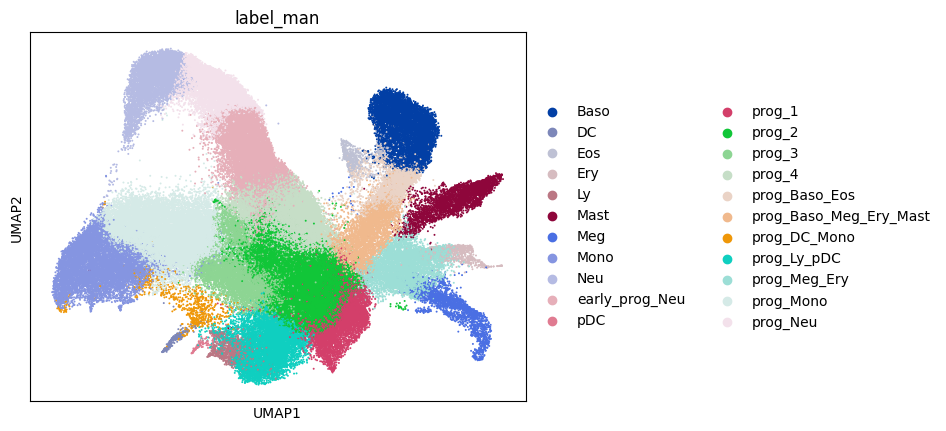

In [25]:
sc.pl.umap(adata, color='label_man', s=8) #, legend_loc='on data')

/path/to/hpc-work/LIBS/mamba/envs/LARRY_env/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not 

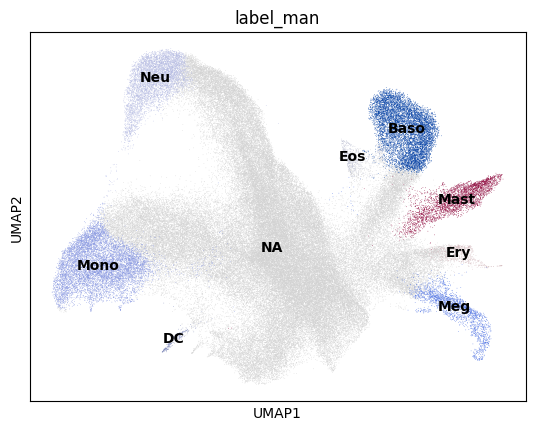

In [26]:
TERMINAL = ['Baso', 'DC', 'Eos', 'Ery', 'Mast', 'Meg', 'Mono', 'Neu']
sc.pl.umap(adata, color='label_man', groups=TERMINAL, legend_loc='on data')

In [27]:
adata.obs

,Library,Cell barcode,day,population,cell_type,Well,SPRING-x,SPRING-y,LARRY_ID,condition,neutrophil_pseudotime,neutrophil_monocyte_trajectory,label_man,cell_type_weinreb
cell_0,d6_2_2,GCGTGCAA-AGAAGTTA,6,Lin-Kit+Sca1-,prog_2,2,411.496,-96.190,Clone_573,Control,23849.0,True,prog_2,Undifferentiated
cell_1,d6_2_2,AAGGGACC-CTCGATGC,6,Lin-Kit+Sca1-,prog_Baso_Meg_Ery_Mast,2,-587.462,-306.925,Clone_1440,Control,NaN,False,prog_Baso_Meg_Ery_Mast,Undifferentiated
cell_2,d6_2_2,CGTACCGA-AGCGCCTT,6,Lin-Kit+Sca1-,prog_Mono,2,1429.805,-429.300,Clone_394,Control,NaN,True,prog_Mono,Monocyte
cell_3,d6_2_2,CTGAAGGG-AGGAGCTT,6,Lin-Kit+Sca1-,early_prog_Neu,2,1150.028,-2030.369,,Control,48995.0,True,early_prog_Neu,Neutrophil
cell_4,d6_2_2,CCGTAGCT-AGGCAGTT,6,Lin-Kit+Sca1-,prog_Meg_Ery,2,-1169.594,362.010,Clone_1972,Control,NaN,False,prog_Meg_Ery,Undifferentiated
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
cell_130882,LSK_d6_1_3,TCTGATTT-CGGGCTTT,6,Lin-Kit+Sca1+,prog_Baso_Meg_Ery_Mast,1,-308.468,-163.223,,Control,NaN,False,prog_Baso_Meg_Ery_Mast,Undifferentiated
cell_130883,LSK_d6_1_3,AGTCACAA-TGTGTCCT,6,Lin-Kit+Sca1+,prog_2,1,-3.435,575.133,Clone_1374,Control,9126.0,True,prog_2,Undifferentiated
cell_130884,LSK_d6_1_3,GGAGGTTT-AGGCAGTT,6,Lin-Kit+Sca1+,Mono,1,2548.309,24.683,,Control,NaN,True,Mono,Monocyte
cell_130885,LSK_d6_1_3,CCGGAAAT-GGGAAGGT,6,Lin-Kit+Sca1+,Mono,1,2658.601,131.098,,Control,NaN,True,Mono,Monocyte


/path/to/hpc-work/LIBS/mamba/envs/LARRY_env/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not 

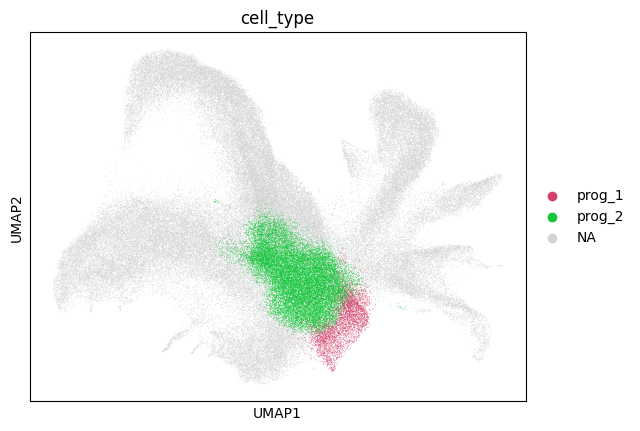

In [28]:
sc.pl.umap(adata, color='cell_type', groups=['prog_1', 'prog_2'])

/path/to/hpc-work/LIBS/mamba/envs/LARRY_env/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not 

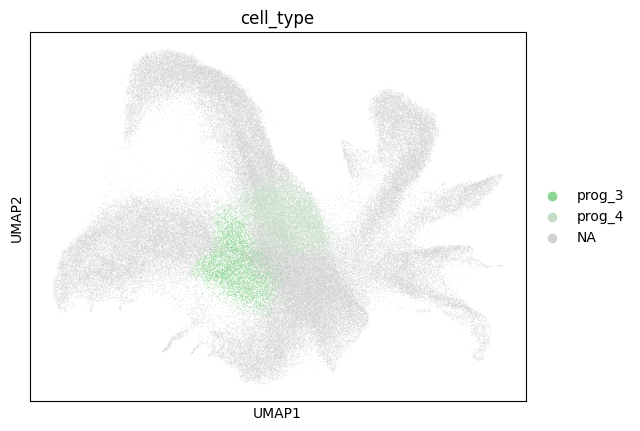

In [29]:
sc.pl.umap(adata, color='cell_type', groups=['prog_3', 'prog_4'])

## 1. Lineage Continuity Filtering
Filter for clones with progenitor origin at Day 2 and consecutive temporal persistence.

In [30]:
# Determine the progenitor labels at day 2
start_cell_types = ['prog_1', 'prog_2']
print(f"Start cell types allowed at Day 2: {start_cell_types}")

# Apply filtering
adata_ctrl = cc.preprocessing.filter_lineage_continuity(
    adata,
    condition_key='condition',
    condition_val='Control',
    day_key='day',
    cell_type_key='cell_type',
    start_cell_type=start_cell_types,
    barcode_key='LARRY_ID',
    min_persistence=2  # Require Day 2 + Day 4
)

Start cell types allowed at Day 2: ['prog_1', 'prog_2']
Starting lineage filtration for Condition: 'Control'...
Start cell type(s): {'prog_1', 'prog_2'}
Detected time points: [2, 4, 6]
Valid Start barcodes at Day 2: 1241
Barcodes passing continuity filter (min 2 timepoints): 784

VERIFICATION REPORT
Original Cells : 126861
Filtered Cells : 9714 (7.66%)

Day 2 Composition:
cell_type
prog_2                    786
prog_1                    255
prog_Mono                   0
prog_Meg_Ery                0
prog_Ly_pDC                 0
prog_DC_Mono                0
prog_Baso_Meg_Ery_Mast      0
prog_Baso_Eos               0
prog_4                      0
prog_3                      0
Baso                        0
DC                          0
early_prog_Neu              0
Neu                         0
Mono                        0
Meg                         0
Mast                        0
Ly                          0
Ery                         0
Eos                         0
prog_Neu       

## 2. Clone Table Construction & Normalization
Build the clones × (time & feature) table and normalize by sample totals.

In [31]:
times_order = [2, 4, 6]
features_order = sorted([str(x) for x in adata_ctrl.obs['cell_type'].unique()])

print(f"Times: {times_order}")
print(f"Features: {features_order}")

clone_table = cc.preprocessing.build_clone_table(
    adata_ctrl,
    clone_id_col='LARRY_ID',
    time_col='day',
    feature_col='cell_type',
    time_prefix='Day',
    feature_prefix='',
    times_order=times_order,
    features_order=features_order,
    min_total_count=0
)

# In Weinreb, we can treat all as one single experiment/sample
norm_table = cc.normalization.normalize_clone_table(
    clone_table,
    times_order=[f"Day{t}" for t in times_order],
    features_order=features_order,
    time_prefix='Day',
    feature_prefix='',
    sample_id_extractor=lambda idx: pd.Series(['S1'] * len(idx), index=idx)
)
norm_table

Times: [2, 4, 6]
Features: ['Baso', 'DC', 'Eos', 'Ery', 'Ly', 'Mast', 'Meg', 'Mono', 'Neu', 'early_prog_Neu', 'prog_1', 'prog_2', 'prog_3', 'prog_4', 'prog_Baso_Eos', 'prog_Baso_Meg_Ery_Mast', 'prog_DC_Mono', 'prog_Ly_pDC', 'prog_Meg_Ery', 'prog_Mono', 'prog_Neu']


,Day2_prog_1,Day2_prog_2,Day4_Baso,Day4_DC,Day4_Eos,Day4_Ery,Day4_Ly,Day4_Mast,Day4_Meg,Day4_Mono,...,Day6_prog_2,Day6_prog_3,Day6_prog_4,Day6_prog_Baso_Eos,Day6_prog_Baso_Meg_Ery_Mast,Day6_prog_DC_Mono,Day6_prog_Ly_pDC,Day6_prog_Meg_Ery,Day6_prog_Mono,Day6_prog_Neu
LARRY_ID,,,,,,,,,,,,,,,,,,,,,
Clone_10,1.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.900000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0
Clone_15,0.000000,1.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,0.444444,0.277778,0.0,0.0,0.0,0.000000,0.0
Clone_21,0.000000,1.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.100000,0.0,0.200000,0.000000,0.000000,0.0,0.0,0.0,0.700000,0.0
Clone_38,0.333333,0.666667,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.214286,0.0,0.214286,0.000000,0.000000,0.0,0.0,0.0,0.428571,0.0
Clone_50,0.000000,1.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Clone_5705,0.000000,1.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0
Clone_5710,0.000000,1.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0
Clone_5777,1.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0


## 3. Consensus Clustering
Build the multi-resolution Leiden consensus matrix.

In [32]:
# This step is computationally intensive
filtered_table, trajectory_adata, consensus_matrix = cc.consensus.build_consensus_matrix(
    norm_table,
    min_cells=3,
    adata_full=adata_ctrl,
    clone_id_col='LARRY_ID',
    n_neighbors=30,
    resolutions=np.arange(1.1, 4.1, 0.1)
)

print(f"Clones passing min_cells filter: {filtered_table.shape[0]}")

2026-07-24 12:13:55.197729: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-07-24 12:14:09.849309: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-07-24 12:14:50.459448: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


Clones passing min_cells filter: 713


## 4. Metaclone Assignment
Sweep distance thresholds and use silhouette scoring to find the optimal agglomerative clustering threshold.

In [33]:
consensus_distance = 1 - consensus_matrix

(thresholds, silhouette_scores, cluster_counts, 
 optimal_threshold, final_labels, 
 sample_silhouette_values) = cc.clustering.sweep_thresholds(
    consensus_distance=consensus_distance,
    filtered_table=filtered_table,
    thresholds=np.arange(0.01, 0.91, 0.01)
)

print(f"\nOptimal threshold: {optimal_threshold:.3f}")
print(f"Number of metaclones: {len(np.unique(final_labels))}")
print(f"Best silhouette score: {max(silhouette_scores):.3f}")

Starting threshold sweep...

Selected threshold : 0.56
Max silhouette score: 0.245
Clusters            : 25

Optimal threshold: 0.560
Number of metaclones: 25
Best silhouette score: 0.245


## 5. Filtering and Visualization
Remove low-quality clones and small metaclones, and visualize silhouette scores before and after.

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

Silhouette Plot BEFORE filtering:


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

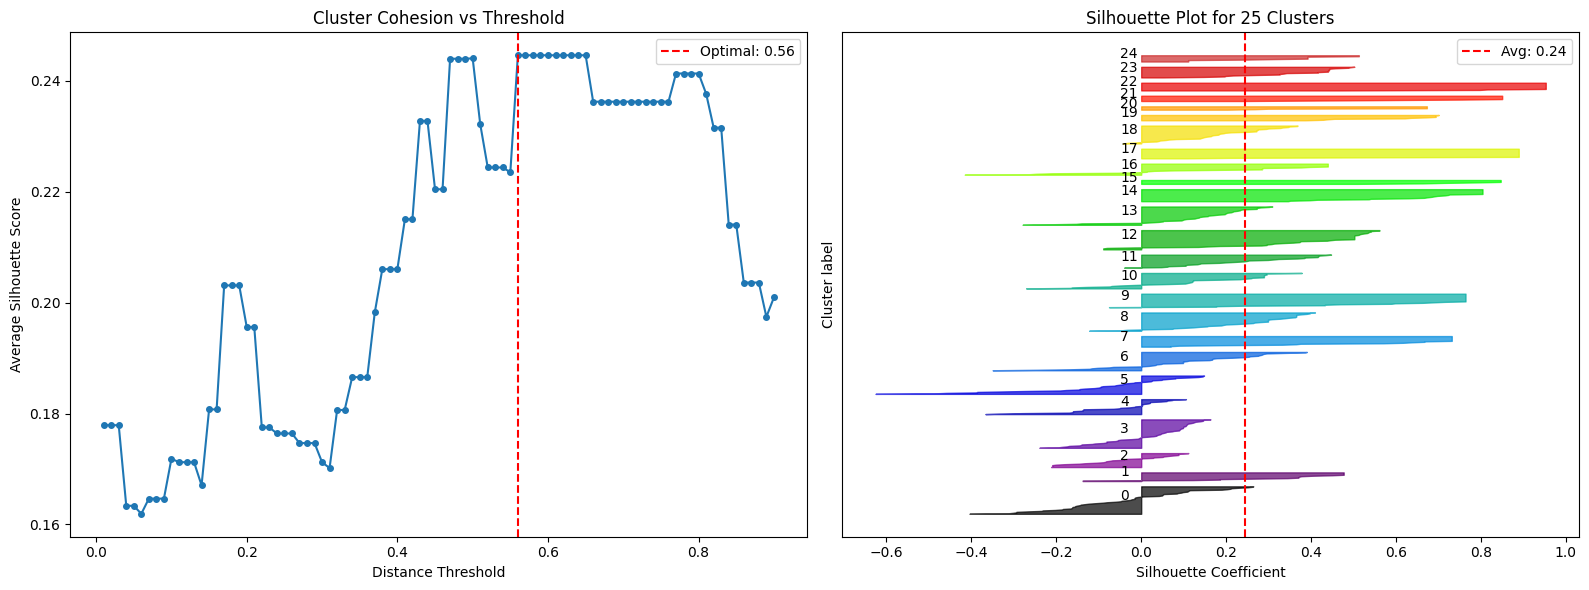

In [34]:
# 5.1 Silhouette Plot BEFORE filtering
print("Silhouette Plot BEFORE filtering:")
cc.visualization.plot_threshold_and_silhouette(
    thresholds, silhouette_scores, cluster_counts,
    optimal_threshold, max(silhouette_scores),
    filtered_table, final_labels, sample_silhouette_values
)

In [35]:
# Remove clones with silhouette score < -1.0 and metaclones that have less than 15 clones
print(f"Clones before filtering: {len(final_labels)}")

mask_sil = sample_silhouette_values >= -0.1

mc_counts = pd.Series(final_labels).value_counts()
valid_mcs = mc_counts[mc_counts >= 15].index
mask_mc = pd.Series(final_labels).isin(valid_mcs).values

mask_keep = mask_sil & mask_mc

# Update arrays and dataframes
final_labels_filtered = final_labels[mask_keep]
filtered_table_filtered = filtered_table.iloc[mask_keep]
trajectory_adata_filtered = trajectory_adata[mask_keep].copy()
sample_silhouette_values_filtered = sample_silhouette_values[mask_keep]

print(f"Clones after filtering: {len(final_labels_filtered)}")
print(f"Metaclones remaining: {len(np.unique(final_labels_filtered))}")

Clones before filtering: 713
Clones after filtering: 569
Metaclones remaining: 20


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

Silhouette Plot AFTER filtering:


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

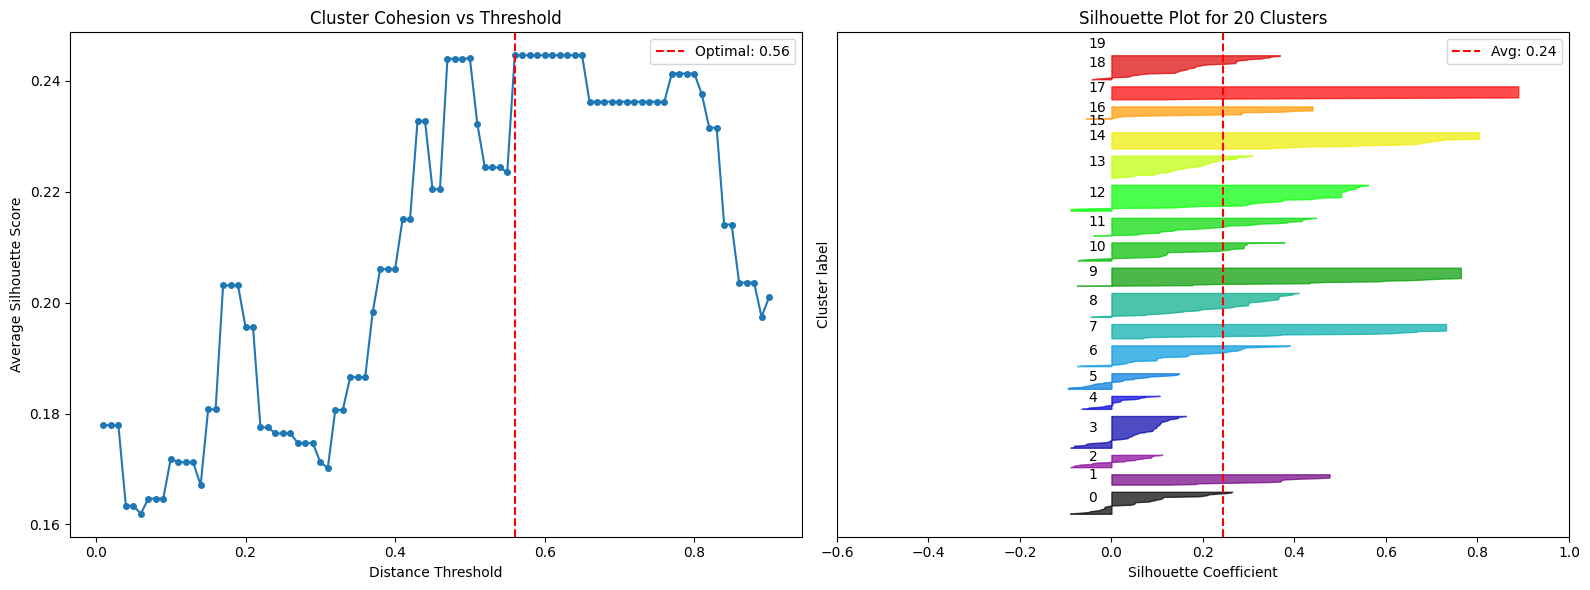

In [36]:
# 5.2 Silhouette Plot AFTER filtering
print("Silhouette Plot AFTER filtering:")
cc.visualization.plot_threshold_and_silhouette(
    thresholds, silhouette_scores, cluster_counts,
    optimal_threshold, max(silhouette_scores),
    filtered_table_filtered, final_labels_filtered, sample_silhouette_values_filtered
)

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

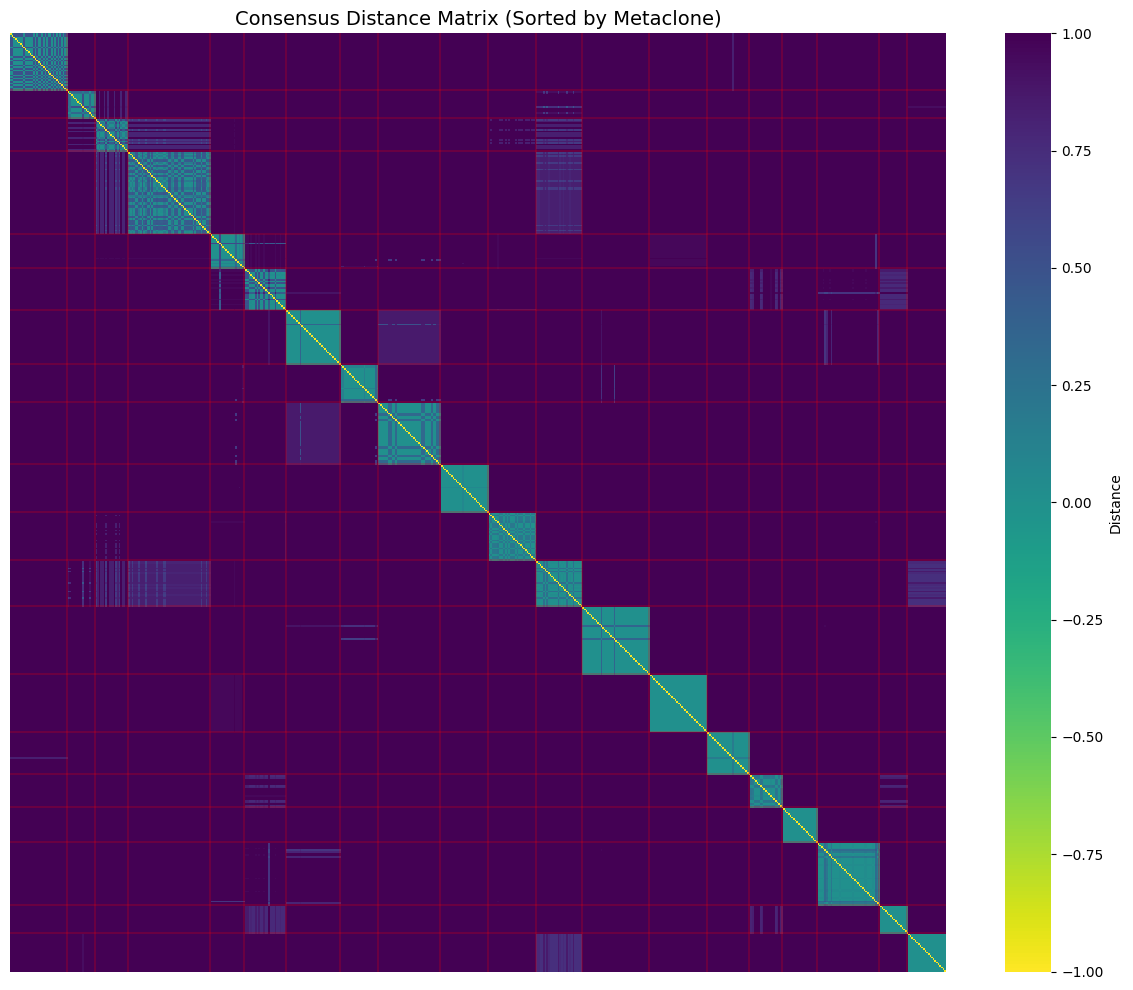

In [37]:
# 5.3 Consensus Heatmap
cc.visualization.plot_consensus_heatmap(
    consensus_distance[mask_keep][:, mask_keep], final_labels_filtered, linewidth=0.3
)

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

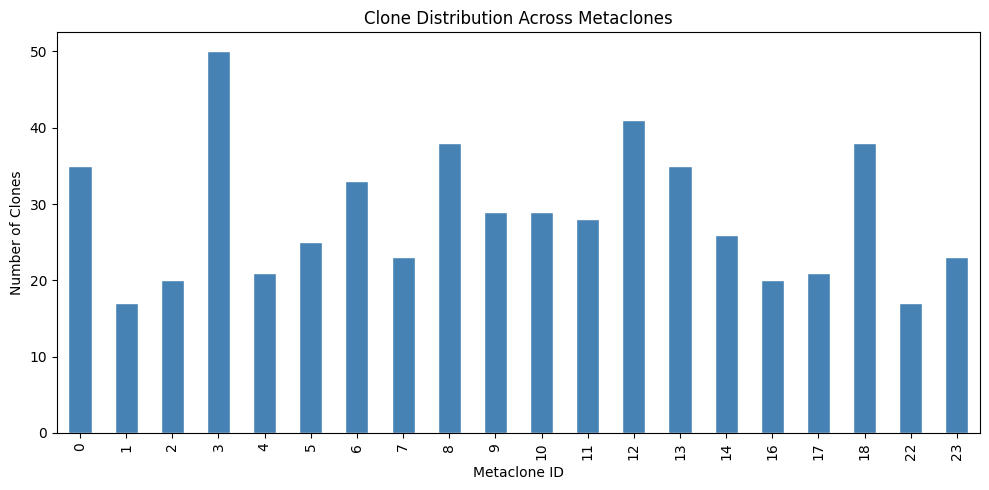

In [38]:
# 5.4 Metaclone Size Distribution
cc.visualization.plot_cluster_distribution(final_labels_filtered, color='steelblue')

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

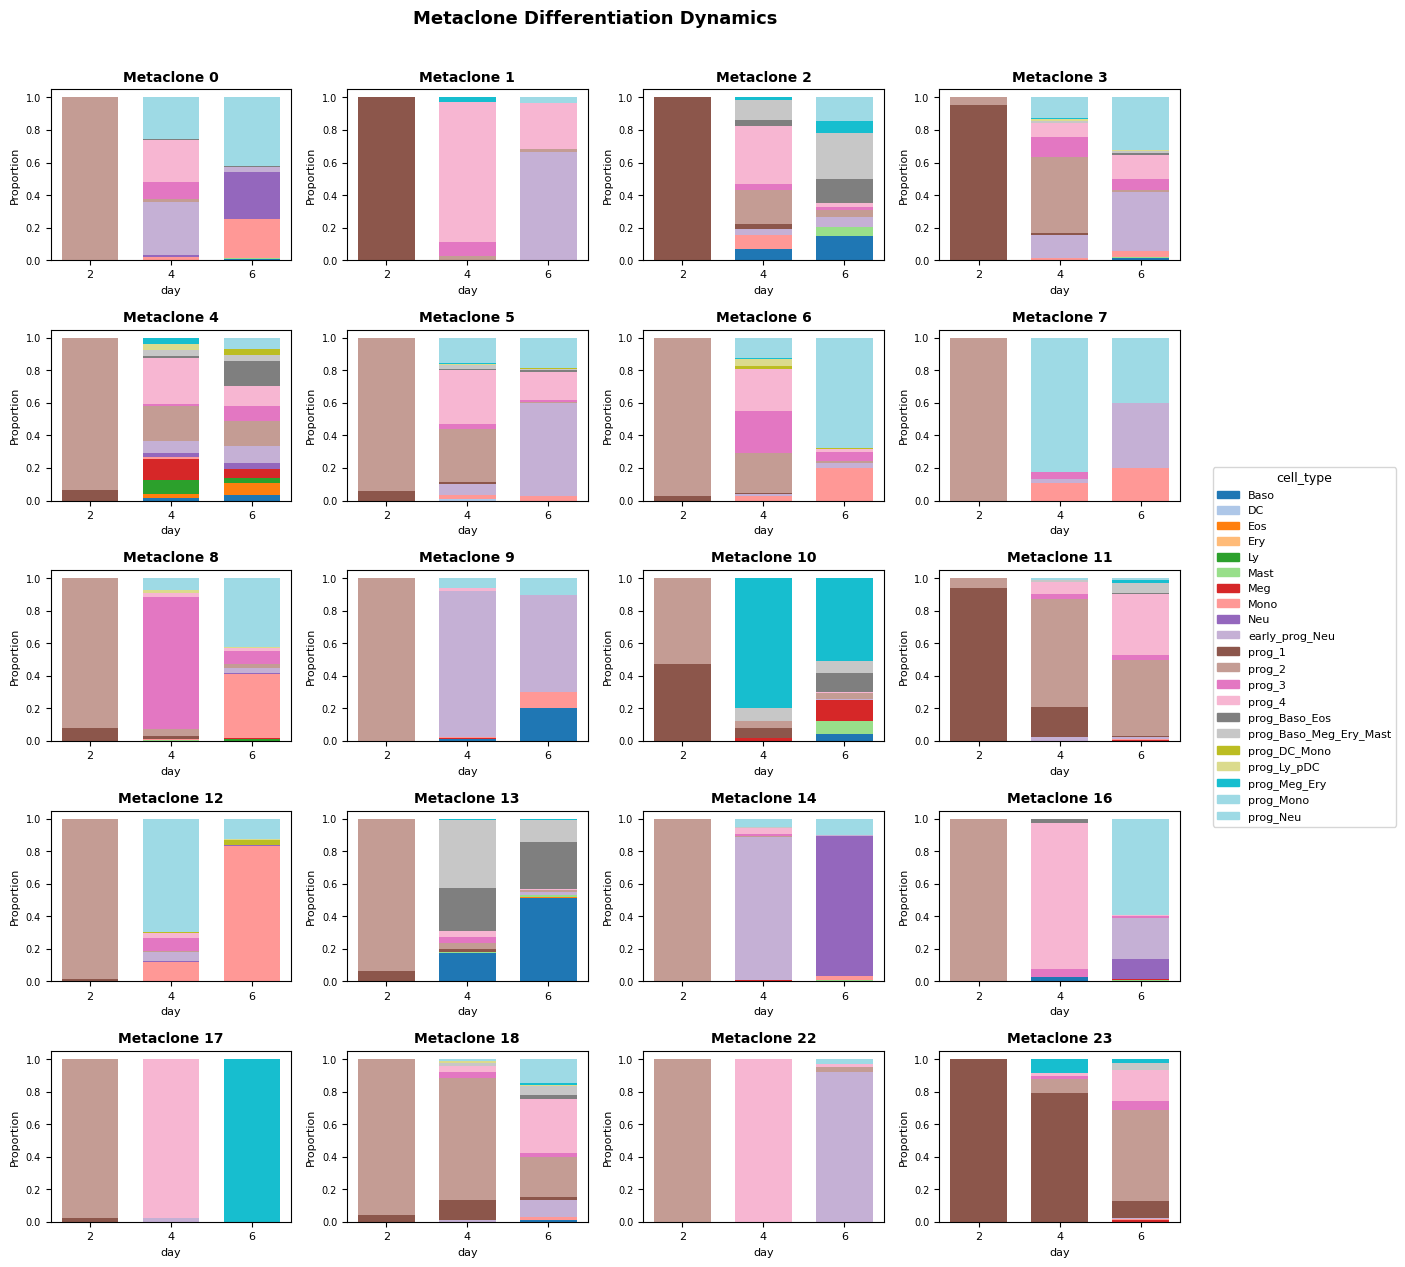

In [39]:
# Transfer Labels
adata_ctrl = cc.clustering.transfer_metaclone_labels(
    adata_ctrl, trajectory_adata_filtered, final_labels_filtered,
    clone_id_col='LARRY_ID', target_col='metaclone'
)

# Convert metaclone to int type
adata_ctrl.obs['metaclone'] = adata_ctrl.obs['metaclone'].astype(float).fillna(-1).astype(int)

# 5.5 Metaclone Dynamics (Stacked bars)
# Filtering out -1 before plotting dynamics is recommended
adata_mc = adata_ctrl[adata_ctrl.obs['metaclone'] != -1].copy()

cc.visualization.plot_metaclone_dynamics(
    adata_mc,
    metaclone_key='metaclone',
    time_key='day',
    feature_key='cell_type',
    normalize=True,
    figsize_per_metaclone=(3, 2.5),
    palette='tab20'
)

In [41]:
adata_ctrl.obs.metaclone.value_counts()

metaclone
-1     1981
 0     1224
 3      999
 6      575
 12     567
 13     544
 8      533
 18     493
 11     427
 14     403
 5      362
 10     269
 23     205
 16     205
 9      173
 4      166
 2      149
 7      127
 22     115
 1      107
 17      90
Name: count, dtype: int64

## 6. Retrospective DE Analysis (Day 2 Progenitors)
Determine if metaclone identities are already transcriptionally encoded at Day 2.

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,Slc7a5,5.649430,1.417137,1.609809e-08,0.000182
1,0,Prtn3,5.628183,1.463755,1.821176e-08,0.000182
2,0,Atp5j2,5.564755,1.435688,2.625201e-08,0.000182
3,0,Atp5g3,5.173567,1.028719,2.296671e-07,0.001159
4,0,Golga3,5.139822,1.192762,2.749989e-07,0.001159
5,0,BC051077,5.110452,1.228276,3.213897e-07,0.001161
6,0,Ms4a3,4.887986,1.278172,1.018726e-06,0.002975
7,0,Cycs,4.877050,1.303755,1.076839e-06,0.002975
8,0,Cox7a2,4.836120,1.177338,1.323984e-06,0.002975
10,0,Snrpd3,4.807374,1.208928,1.529258e-06,0.002975


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

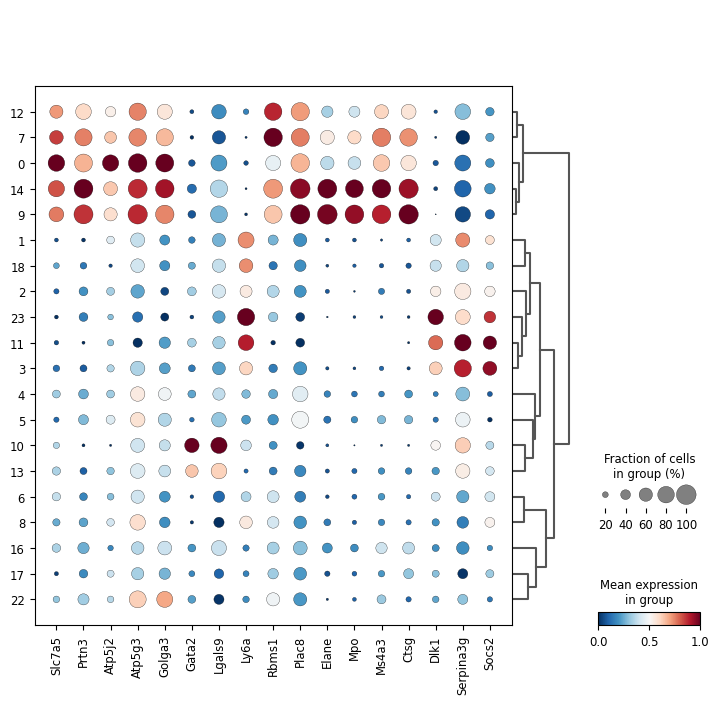

In [42]:
# 1. Subset to Day 2 cells with a valid metaclone
adata_day2 = adata_ctrl[
    (adata_ctrl.obs['day'] == 2) & 
    (adata_ctrl.obs['metaclone'] != -1)
].copy()

# Convert 'metaclone' to string FIRST, then to categorical dtype
adata_day2.obs['metaclone'] = adata_day2.obs['metaclone'].astype(str).astype('category')

# 2. Perform DE analysis (One vs Rest)
sc.tl.rank_genes_groups(adata_day2, groupby='metaclone', method='wilcoxon')

# 3. Extract the DE dataframe
de_df = sc.get.rank_genes_groups_df(adata_day2, group=None)

# 4. Filter the dataframe based on p-value and log fold-change manually
padj_cutoff = 0.05
logfc_cutoff = 1.0
top_n = 5 # Number of top genes to plot per metaclone

# Filter for significant and highly expressed markers
filtered_df = de_df[
    (de_df['pvals_adj'] < padj_cutoff) & 
    (de_df['logfoldchanges'] > logfc_cutoff)
]

# Extract the top N valid genes per group for the dotplot
top_genes_per_group = (
    filtered_df.groupby('group')
    .head(top_n)['names']
    .unique()
    .tolist()
)

display(filtered_df.head(10))

# Save the filtered DE table (Commented out so it does not save)
# filtered_df.to_csv(f"day2_metaclone_filtered_DE_{date_str}.csv", index=False)

# Compute dendrogram for the metaclones to cluster them based on expression
sc.tl.dendrogram(adata_day2, groupby='metaclone')

# 5. Plot Dotplot passing the EXACT list of filtered marker genes
sc.pl.dotplot(
    adata_day2, 
    var_names=top_genes_per_group, 
    groupby='metaclone',
    standard_scale='var', # Color maps from 0 to 1 representing min/max mean expression across groups
    cmap='RdBu_r',        # Set colormap
    dendrogram=True,      # Keep dendrogram clustering
    show=True
)

## 7. Metaclone-resolved UMAP Density Plots
Visualize how each metaclone traverses the UMAP landscape over time.

Pre-calculating density scales per metaclone...
Scales calculated.




array([-1,  0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 16,
       17, 18, 22, 23])

In [ ]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
import warnings
import logging

adata_plot = adata_ctrl.copy()
N_neighbors = 100

# Mute warnings
warnings.filterwarnings("ignore")
sc.settings.verbosity = 0
logging.getLogger("scanpy").setLevel(logging.ERROR)

# Get unique days and clusters
unique_days = np.sort(adata_plot.obs['day'].unique())
unique_clusters = np.sort(adata_plot.obs.metaclone.unique())

# --- Step 1: Build Global Nearest Neighbors on Full Background ---
full_umap = adata_plot.obsm['X_umap']
# k=N_neighbors neighbors (BallTree for speed)
nbrs = NearestNeighbors(n_neighbors=N_neighbors, algorithm='ball_tree').fit(full_umap)

# --- Step 1b: Pre-calculate VMAX per Metaclone ---
metaclone_vmax = {}

print("Pre-calculating density scales per metaclone...")

for cluster in unique_clusters:
    max_density_seen = 0
    
    for day in unique_days:
        subset_mask = (adata_plot.obs['day'] == day) & (adata_plot.obs['metaclone'] == cluster)
        subset_indices = np.where(subset_mask)[0]
        
        if len(subset_indices) > 0:
            subset_coords = full_umap[subset_indices]
            distances, indices = nbrs.kneighbors(subset_coords)
            
            subset_idx_set = set(subset_indices)
            
            densities = []
            for neighbor_row in indices:
                match_count = sum(1 for idx in neighbor_row if idx in subset_idx_set)
                densities.append(match_count)
            
            if densities:
                max_density_seen = max(max_density_seen, max(densities))
    
    metaclone_vmax[cluster] = max(max_density_seen, 5)

print("Scales calculated.")

# --- Step 2: Plotting ---
ncols = len(unique_clusters)
nrows = len(unique_days)
fig, axs = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows))
axs = axs.flatten()

plot_idx = 0
for day in unique_days:
    for cluster in unique_clusters:
        ax = axs[plot_idx]
        plot_idx += 1

        # Plot Background
        sc.pl.umap(
            adata_ctrl,
            color=None,
            ax=ax,
            show=False,
            title='',
            s=300,
            alpha=0.1,
            add_outline=True,                 
            outline_color=('black', 'white'), 
            outline_width=(0.3, 0.01)         
        )
        ax.set_xlabel('')
        ax.set_ylabel('')
        ax.set_xticks([])
        ax.set_yticks([])

        # Identify indices of the subset
        subset_mask = (adata_plot.obs['day'] == day) & (adata_plot.obs['metaclone'] == cluster)
        subset_indices = np.where(subset_mask)[0]
        
        subset_n_obs = len(subset_indices)
        
        if subset_n_obs > 0:
            # Coordinates
            subset_coords = full_umap[subset_indices]
            
            # Neighbors
            distances, indices = nbrs.kneighbors(subset_coords)
            
            # Density / Purity
            subset_idx_set = set(subset_indices)
            
            densities = []
            for neighbor_row in indices:
                match_count = sum(1 for idx in neighbor_row if idx in subset_idx_set)
                densities.append(match_count)
            
            densities = np.array(densities)
            
            # Sort
            sort_idx = densities.argsort()
            x_sorted = subset_coords[sort_idx, 0]
            y_sorted = subset_coords[sort_idx, 1]
            z_sorted = densities[sort_idx]

            # Use the pre-calculated VMAX for this specific metaclone
            current_vmax = metaclone_vmax[cluster]

            scatter_plot = ax.scatter(
                x_sorted,
                y_sorted,
                c=z_sorted,
                cmap='viridis',
                s=350,
                alpha=0.9,
                # NEW: black outlines for foreground points
                edgecolors='black',   
                linewidths=0.3,       
                vmin=0,
                vmax=current_vmax
            )

# Hide unused axes
for j in range(plot_idx, len(axs)):
    axs[j].set_visible(False)

plt.tight_layout()
plt.show()
unique_clusters

## 8. Save

Because the analysis object was built with the full gene matrix up front,
`adata_ctrl` already carries all genes + LARRY_ID + metaclone labels — no
post-hoc gene reconstruction is needed. Save it directly.

In [43]:
# Full control object (all genes, LARRY_ID, metaclone labels)
adata_ctrl.write('klein_metaclone.h5ad')
adata_ctrl

AnnData object with n_obs × n_vars = 9714 × 25289
    obs: 'Library', 'Cell barcode', 'day', 'population', 'cell_type', 'Well', 'SPRING-x', 'SPRING-y', 'LARRY_ID', 'condition', 'neutrophil_pseudotime', 'neutrophil_monocyte_trajectory', 'label_man', 'cell_type_weinreb', 'metaclone'
    var: 'gene_symbol'
    uns: 'log1p', 'label_man_colors', 'cell_type_colors'
    obsm: 'clone_matrix', 'X_umap'

In [44]:
# Metaclone-assigned cells only
adata_valid = adata_ctrl[adata_ctrl.obs.metaclone != -1].copy()
adata_valid.write('klein_metaclone_valid_only.h5ad')
adata_valid

AnnData object with n_obs × n_vars = 7733 × 25289
    obs: 'Library', 'Cell barcode', 'day', 'population', 'cell_type', 'Well', 'SPRING-x', 'SPRING-y', 'LARRY_ID', 'condition', 'neutrophil_pseudotime', 'neutrophil_monocyte_trajectory', 'label_man', 'cell_type_weinreb', 'metaclone'
    var: 'gene_symbol'
    uns: 'log1p', 'label_man_colors', 'cell_type_colors'
    obsm: 'clone_matrix', 'X_umap'

In [ ]:
list(adata.obs.cell_type.unique())

['prog_2',
 'prog_Baso_Meg_Ery_Mast',
 'prog_Mono',
 'prog_Meg_Ery',
 'prog_Neu',
 'early_prog_Neu',
 'prog_4',
 'prog_Baso_Eos',
 'Ery',
 'Meg',
 'prog_3',
 'Neu',
 'Mono',
 'Mast',
 'Baso',
 'Ly',
 'prog_Ly_pDC',
 'prog_DC_Mono',
 'Eos',
 'prog_1',
 'DC',
 'pDC']

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

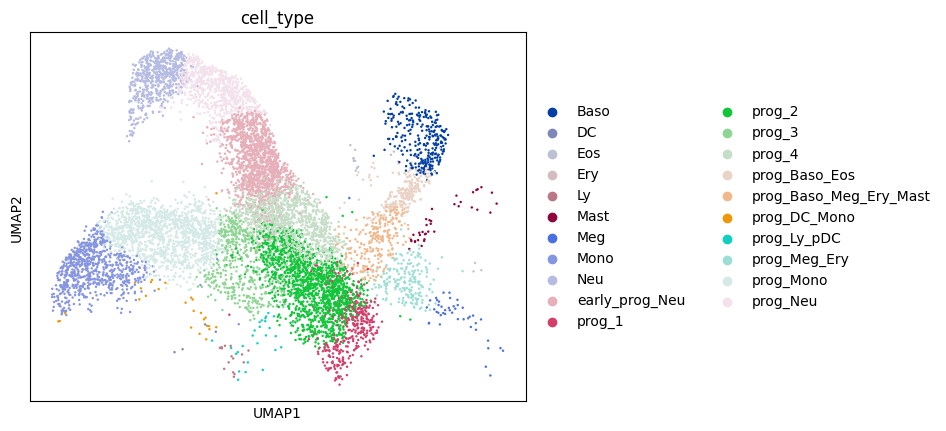

In [45]:
sc.pl.umap(adata_ctrl, color='cell_type')